# Hipótesis 4 · Especies según actividad y ubicación (GSAF)

**Hipótesis:** las especies identificadas presentan distintas distribuciones según la actividad y la ubicación del incidente.
**Pregunta:** ¿qué especies aparecen con mayor frecuencia en las distintas actividades y zonas geográficas?

Requiere `pandas`, `scipy`, `seaborn`, `matplotlib` y `xlrd` (para leer `.xls`).

## 1. Carga

In [1]:
import re
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

df = pd.read_excel("GSAF5_limpio.xls")
df.columns = df.columns.str.strip()            # "Species " tenía un espacio al final
df = df[df["Type"].astype(str).str.strip().str.lower() != "invalid"]   # incidentes no válidos
print(df.shape)
df[["Country", "Activity", "Species"]].head()

(6573, 27)


,Country,Activity,Species
0,Australia,Swimming,Great white shark 6m
1,Canada,Diving,Great white shark
2,Bahamas,Swimming,Unknown
3,Australia,Surfing,Unknown
4,Usa,Surfing,Tiger shark suspected


## 2. Limpieza
`Species` y `Activity` son texto libre (más de 1.300 valores distintos cada uno). Se agrupan con reglas por palabras clave; la primera regla que coincide gana, por eso el orden importa (p. ej. *sand tiger* antes que *tiger*). Lo que no coincide con ninguna especie queda como **Sin identificar**.

In [2]:
def clasificar(texto, reglas, defecto):
    t = str(texto).lower()
    for etiqueta, patron in reglas:
        if re.search(patron, t):
            return etiqueta
    return defecto

ESPECIES = [
    ("Oceánico punta blanca", r"oceanic white|longimanus"),
    ("Arrecife",              r"reef|whitetip"),
    ("Sand tiger / grey nurse", r"sand ?tiger|grey nurse|gray nurse|ragged ?tooth|sand ?shark"),
    ("Blanco",                r"white shar|great white|white pointer|\bgws\b|carcharodon"),
    ("Tigre",                 r"tiger"),
    ("Toro",                  r"\bbull\b|zambesi|zambezi|leucas"),
    ("Punta negra / spinner", r"blacktip|spinner|limbatus"),
    ("Nodriza",               r"nurse"),
    ("Wobbegong",             r"wobbegong|carpet"),
    ("Azul",                  r"blue shark|blue whaler"),
    ("Mako",                  r"mako|blue pointer"),
    ("Limón",                 r"lemon"),
    ("Martillo",              r"hammerhead"),
    ("Cobrizo / whaler",      r"whaler|bronze|copper"),
]
ACTIVIDADES = [
    ("Pesca submarina",   r"spear"),
    ("Naufragio / caída al agua", r"disaster|wreck|overboard|capsiz|sank|sunk|aircraft|torpedo"),
    ("Pesca",             r"fish"),
    ("Buceo",             r"div|snorkel|scuba"),
    ("Surf y tablas",     r"surf|board|paddle|kite"),
    ("Natación y baño",   r"swim|bath|wad|stand|float|tread|walk|play"),
    ("Embarcaciones",     r"kayak|canoe|row|boat|sail"),
]

# Texto con dos especies ("bull or tiger") → ambiguo; se descarta como no identificado
df["especie"]   = df["Species"].apply(lambda t: "Sin identificar" if re.search(r"\bor\b|&", str(t).lower())
                                      else clasificar(t, ESPECIES, "Sin identificar"))
df["actividad"] = df["Activity"].apply(lambda t: clasificar(t, ACTIVIDADES, "Otras / desconocida"))

# Zona: los 6 países con más registros identificados; el resto, agrupado
ident = df[df["especie"] != "Sin identificar"].copy()
pais = df["Country"].str.title().replace({"Usa": "USA"})
top_paises = pais[df["especie"] != "Sin identificar"].value_counts().head(6).index
df["zona"] = pais.where(pais.isin(top_paises), "Resto del mundo")
ident = df[df["especie"] != "Sin identificar"].copy()

print(f"Registros: {len(df):,} · con especie identificada: {len(ident):,} ({len(ident)/len(df):.0%})")

Registros: 6,573 · con especie identificada: 2,058 (31%)


## 3. Especies más frecuentes (visión global)

especie
Blanco                     34.2
Tigre                      14.8
Toro                       13.0
Sand tiger / grey nurse     6.5
Punta negra / spinner       5.1
Arrecife                    4.4
Cobrizo / whaler            4.3
Nodriza                     3.5


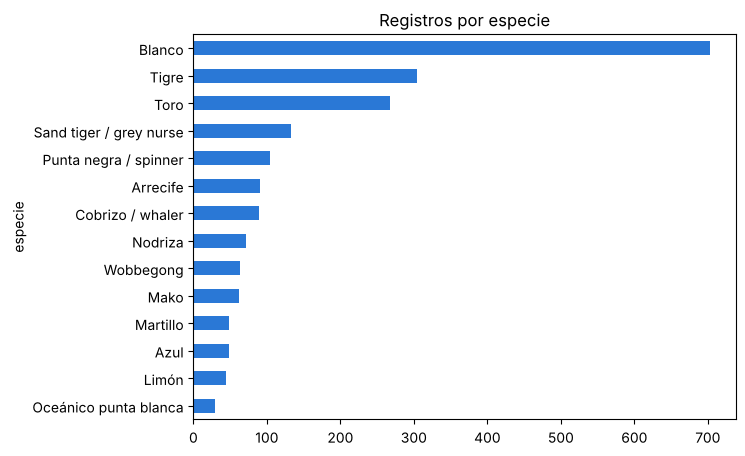

In [3]:
frecuencia = ident["especie"].value_counts()
print((frecuencia / len(ident) * 100).round(1).head(8).to_string())
frecuencia.sort_values().plot.barh(figsize=(7, 5), color="#2a78d6", title="Registros por especie")
plt.show()

## 4. Especies por actividad y por zona
`distribucion` calcula, para cada actividad o zona (con ≥ 30 registros identificados), el **% de cada especie** dentro de ella. Se muestran las 8 especies más frecuentes.

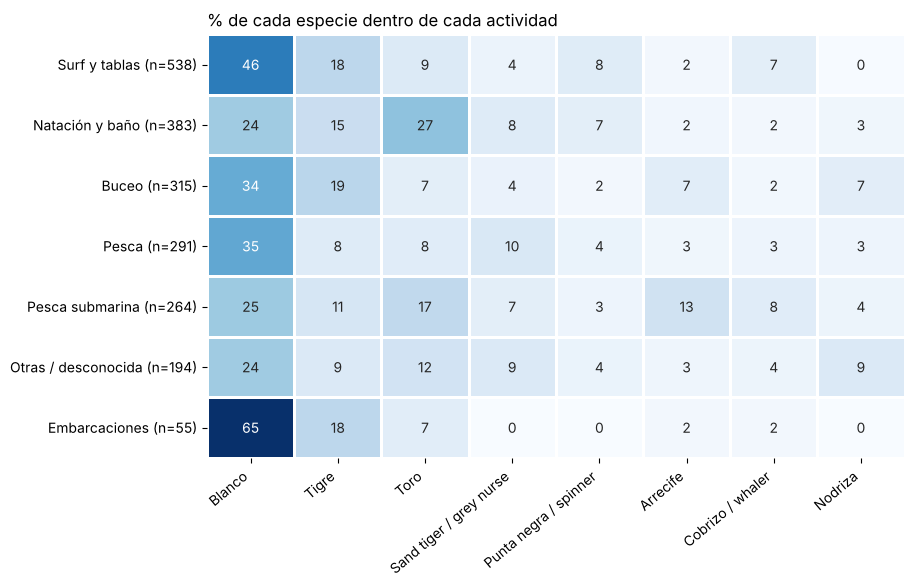

In [4]:
def distribucion(col, min_n=30):
    d = ident[ident[col].map(ident[col].value_counts()) >= min_n]
    top = ident["especie"].value_counts().index[:8]
    tabla = pd.crosstab(d[col], d["especie"], normalize="index")[top] * 100
    n = d[col].value_counts()
    return tabla.loc[n.index], n

def mapa(col, titulo):
    tabla, n = distribucion(col)
    tabla.index = [f"{i} (n={n[i]})" for i in tabla.index]
    plt.figure(figsize=(9, 0.5 * len(tabla) + 2))
    sns.heatmap(tabla, annot=True, fmt=".0f", cmap="Blues", cbar=False, linewidths=1)
    plt.title(titulo, loc="left"); plt.xlabel(""); plt.ylabel("")
    plt.xticks(rotation=40, ha="right"); plt.show()

mapa("actividad", "% de cada especie dentro de cada actividad")

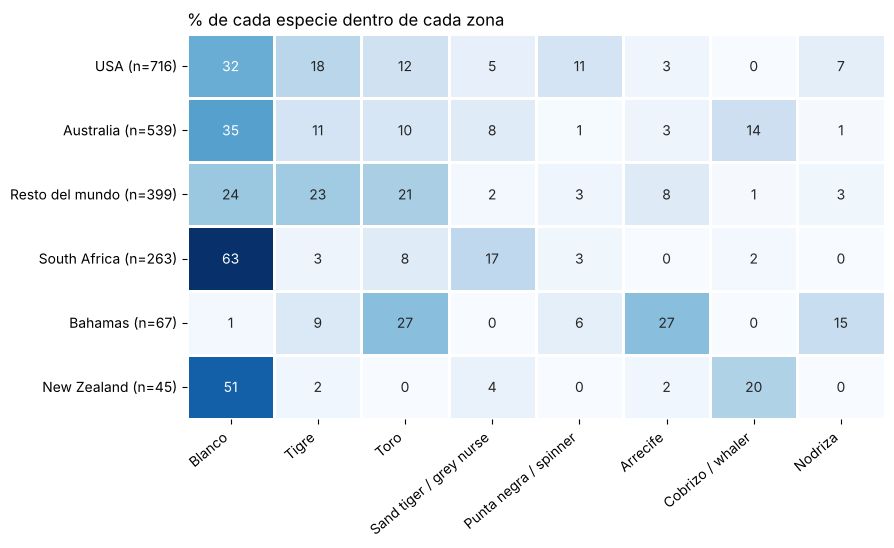

In [5]:
mapa("zona", "% de cada especie dentro de cada zona")

## 5. Conclusiones

### Respuesta a la pregunta: ¿qué especies aparecen con mayor frecuencia?

**El tiburón blanco es la especie más frecuente en casi todas las actividades y zonas.** En conjunto, sobre los 2.058 registros con especie identificada (el 31 % del total): Blanco 34 %, Tigre 15 %, Toro 13 %.

Hay dos excepciones: en **natación y baño** el primero es el **Toro** (27 % frente a 24 % del Blanco), y en **Bahamas** lo son los **tiburones de arrecife y el Toro** (27 % cada uno; el Blanco casi no aparece). Lo que cambia de un grupo a otro es sobre todo qué especies van detrás del Blanco:

**Por actividad** (% sobre los registros identificados de cada actividad)

| Actividad | n | Especies más frecuentes |
|---|---|---|
| Surf y tablas | 538 | Blanco 46 % · Tigre 18 % · Toro 9 % |
| Natación y baño | 383 | **Toro 27 %** · Blanco 24 % · Tigre 15 % |
| Buceo | 315 | Blanco 34 % · Tigre 19 % · Arrecife 7 % |
| Pesca | 291 | Blanco 35 % · Mako 10 % · Sand tiger/grey nurse 10 % |
| Pesca submarina | 264 | Blanco 25 % · Toro 17 % · Arrecife 13 % |
| Embarcaciones | 55 | Blanco 65 % · Tigre 18 % · Toro 7 % |
| Otras / desconocida | 194 | Blanco 24 % · Toro 12 % · Tigre 9 % · Nodriza 9 % |

**Por zona** (% sobre los registros identificados de cada zona)

| Zona | n | Especies más frecuentes |
|---|---|---|
| EE. UU. | 716 | Blanco 32 % · Tigre 18 % · Toro 12 % |
| Australia | 539 | Blanco 35 % · Cobrizo/whaler 14 % · Tigre 11 % |
| Sudáfrica | 263 | **Blanco 63 %** · Sand tiger/grey nurse 17 % · Toro 8 % |
| Nueva Zelanda | 45 | Blanco 51 % · Cobrizo/whaler 20 % · Mako 18 % |
| Bahamas | 67 | **Arrecife 27 % · Toro 27 %** · Nodriza 15 % |
| Resto del mundo | 399 | Blanco 24 % · Tigre 23 % · Toro 21 % |

### ¿Se confirma la hipótesis?

**Sí.** La distribución de especies cambia con la actividad y con la zona (ambos contrastes, p < 0,001). La zona pesa algo más (V de Cramér ≈ 0,31) que la actividad (≈ 0,20); ambas asociaciones son moderadas.

### Limitaciones
* Casi el 70 % de los registros no tiene especie identificada, y la identificación no es aleatoria (es más habitual en buceo y pesca submarina que en naufragios). Las especies grandes y conocidas, como el Blanco, pueden estar sobre-representadas.
* Los grupos pequeños (Embarcaciones, Nueva Zelanda, Bahamas) dan cifras solo orientativas, y el χ² tiene celdas con pocas observaciones.
* Se cuentan incidentes, no riesgo: no hay datos de cuánta gente practica cada actividad en cada zona.
* Actividad y zona están relacionadas entre sí (el surf se concentra en pocos países), así que el análisis no las separa del todo.